In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


### Import the libraries and packages

In [3]:
import numpy as np
from pathlib import Path
from tqdm import trange
import matplotlib.pyplot as plt
from natsort import natsorted
import seaborn as sns
import pandas as pd
import os
from skimage.color import label2rgb
from skimage.color import rgb2gray
from skimage import measure
import tifffile as tiff
import math
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.stats import skew, kurtosis
import scipy.stats as stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Morphology and Intensity features

In [3]:
def extract_features(mask_path, dapi_path):
  mask = tiff.imread(mask_path)
  dapi = tiff.imread(dapi_path)

  #labels = measure.label(mask)
  props = measure.regionprops(mask, intensity_image=dapi)

  data = []

  for prop in props:
      area = prop.area
      perimeter = prop.perimeter if prop.perimeter > 0 else 1

      mean_int = prop.mean_intensity
      std_int = np.std(prop.intensity_image[prop.image])

      data.append({
          "label": prop.label,
          "area": area,
          "perimeter": perimeter,
          "eccentricity": prop.eccentricity,
          "solidity": prop.solidity,
          "extent": prop.extent,
          "major_axis_length": prop.major_axis_length,
          "minor_axis_length": prop.minor_axis_length,

          # Derived shape features
          "circularity": 4 * math.pi * area / (perimeter ** 2),
          "aspect_ratio": prop.major_axis_length / prop.minor_axis_length if prop.minor_axis_length > 0 else 0,
          "compactness": (perimeter ** 2) / area if area > 0 else 0,

          # Intensity features
          "mean_intensity": mean_int,
          "max_intensity": prop.max_intensity,
          "min_intensity": prop.min_intensity,
          "intensity_std": std_int,
          "integrated_intensity": mean_int * area,
          "intensity_range": prop.max_intensity - prop.min_intensity,
          "coefficient_of_variation": std_int / mean_int if mean_int > 0 else 0,

          "centroid_row": prop.centroid[0],
          "centroid_col": prop.centroid[1]
      })

  df = pd.DataFrame(data)

  return df

def well_profile(mask_path, dapi_path):
  df_cells = extract_features(mask_path, dapi_path)

  # Distribution features (per well)
  small_thresh = df_cells["area"].quantile(0.10)
  large_thresh = df_cells["area"].quantile(0.90)

  well_mean = df_cells.mean(numeric_only=True)

  well_mean["area_variance"] = df_cells["area"].var()
  well_mean["area_skewness"] = skew(df_cells["area"])
  well_mean["area_kurtosis"] = kurtosis(df_cells["area"])

  well_mean["percent_small_nuclei"] = (df_cells["area"] < small_thresh).mean() * 100
  well_mean["percent_large_nuclei"] = (df_cells["area"] > large_thresh).mean() * 100

  return well_mean, len(df_cells)


def plate_profile(plate_folder):
    well_profiles = []

    for file in sorted(os.listdir(plate_folder)):
        if file.endswith("_masks.tif"):
            mask_path = os.path.join(plate_folder, file)
            dapi_path = os.path.join(plate_folder, file.replace("_masks", ""))
            wp, count = well_profile(mask_path, dapi_path)
            wp["well_name"] = file
            wp["cell_count"] = count
            well_profiles.append(wp)

    well_profiles = pd.DataFrame(well_profiles)

    plate_mean = well_profiles.mean(numeric_only=True)
    plate_std = well_profiles.std(numeric_only=True)

    return plate_mean, plate_std, well_profiles




In [ ]:
# Define your base paths
base_dir = "/content/drive/MyDrive/Final_Project-Imaging_SEGMENTED/Final_Project"

# Create a configuration list of all your conditions
conditions = [
    {"compound": "DMSO", "conc": "0", "plate": "Week1_22123", "folder": f"{base_dir}/DMSO/Week1_22123"},
    {"compound": "DMSO", "conc": "0", "plate": "Week1_22141", "folder": f"{base_dir}/DMSO/Week1_22141"},
    {"compound": "DMSO", "conc": "0", "plate": "Week1_22161", "folder": f"{base_dir}/DMSO/Week1_22161"},
    {"compound": "DMSO", "conc": "0", "plate": "Week4_27801", "folder": f"{base_dir}/DMSO/Week4_27801"},
    {"compound": "DMSO", "conc": "0", "plate": "Week4_27821", "folder": f"{base_dir}/DMSO/Week4_27821"},
    {"compound": "DMSO", "conc": "0", "plate": "Week4_27861", "folder": f"{base_dir}/DMSO/Week4_27861"},
    # ... add all other folders here ...
    {"compound": "mitomycin C", "conc": "10", "plate": "Week4_27801", "folder": f"{base_dir}/mitomycin/concentration_10/Week4_27801"},
    {"compound": "mitomycin C", "conc": "10", "plate": "Week4_27821", "folder": f"{base_dir}/mitomycin/concentration_10/Week4_27821"},
    {"compound": "mitomycin C", "conc": "10", "plate": "Week4_27861", "folder": f"{base_dir}/mitomycin/concentration_10/Week4_27861"},

    {"compound": "mitomycin C", "conc": "0.003", "plate": "Week4_27801", "folder": f"{base_dir}/mitomycin/concentration_0003/Week4_27801"},
    {"compound": "mitomycin C", "conc": "0.003", "plate": "Week4_27821", "folder": f"{base_dir}/mitomycin/concentration_0003/Week4_27821"},
    {"compound": "mitomycin C", "conc": "0.003", "plate": "Week4_27861", "folder": f"{base_dir}/mitomycin/concentration_0003/Week4_27861"},

    {"compound": "aphidicolin", "conc": "0.003", "plate": "Week1_22123", "folder": f"{base_dir}/aphidicolin/concentration_0003/Week1_22123"},
    {"compound": "aphidicolin", "conc": "0.003", "plate": "Week1_22141", "folder": f"{base_dir}/aphidicolin/concentration_0003/Week1_22141"},
    {"compound": "aphidicolin", "conc": "0.003", "plate": "Week1_22161", "folder": f"{base_dir}/aphidicolin/concentration_0003/Week1_22161"},

    {"compound": "aphidicolin", "conc": "10", "plate": "Week1_22123", "folder": f"{base_dir}/aphidicolin/concentration_10/Week1_22123"},
    {"compound": "aphidicolin", "conc": "10", "plate": "Week1_22141", "folder": f"{base_dir}/aphidicolin/concentration_10/Week1_22141"},
    {"compound": "aphidicolin", "conc": "10", "plate": "Week1_22161", "folder": f"{base_dir}/aphidicolin/concentration_10/Week1_22161"},
]

all_plate_data = []

# Loop through and extract everything into one master list
for cond in conditions:
    if os.path.exists(cond["folder"]):
        plate_mean, plate_std, well_profiles = plate_profile(cond["folder"])

        # Add metadata to your profiles so you know what is what
        well_profiles["compound"] = cond["compound"]
        well_profiles["concentration"] = cond["conc"]
        well_profiles["Plate ID"] = cond["plate"]

        all_plate_data.append(well_profiles)

# Combine into a single master DataFrame
master_df = pd.concat(all_plate_data, ignore_index=True)

# Save for downstream analysis
master_df.to_csv("bbbc021_extracted_features.csv", index=False)

In [ ]:
import pandas as pd
import numpy as np

# Assuming 'master_df' is already created from your code above

# 1. Define your metadata columns so we don't accidentally calculate Z-scores on them
metadata_cols = ['well_name', 'cell_count', 'compound', 'concentration', 'Plate ID']

# Identify all the actual feature columns (area, intensity, etc.)
feature_cols = [col for col in master_df.columns if col not in metadata_cols]

normalized_data = []

# 2. Group by the specific 'Plate ID'
for plate, group_df in master_df.groupby('Plate ID'):

    # Isolate the DMSO wells strictly for this specific plate
    dmso_baseline = group_df[group_df['compound'] == 'DMSO']

    # Check if this plate actually has DMSO controls (safety check)
    if dmso_baseline.empty:
        print(f"Warning: No DMSO controls found for plate {plate}. Skipping normalization for this plate.")
        continue

    # Calculate the mean (µ) and standard deviation (σ) of the DMSO wells on this plate
    dmso_mean = dmso_baseline[feature_cols].mean()
    dmso_std = dmso_baseline[feature_cols].std()

    # Prevent division by zero if a feature is identical across all DMSO cells (std = 0)
    dmso_std = dmso_std.replace(0, np.nan)

    # 3. Apply the Z-score formula to ALL wells on this plate (both DMSO and Treated)
    # Formula: Z = (X - µ_dmso) / σ_dmso
    z_scored_features = (group_df[feature_cols] - dmso_mean) / dmso_std

    # 4. Reconstruct the DataFrame for this plate
    z_scored_group = group_df[metadata_cols].copy()

    # Add the newly calculated z-scored columns with a distinct suffix
    for col in feature_cols:
        z_scored_group[f"{col}_zscore"] = z_scored_features[col]

    normalized_data.append(z_scored_group)

# 5. Combine everything back together into a final DataFrame
master_zscore_df = pd.concat(normalized_data, ignore_index=True)

# Save the properly normalized dataset
master_zscore_df.to_csv("bbbc021_zscored_features_per_plate.csv", index=False)

print("Z-scoring complete! File saved as 'bbbc021_zscored_features_per_plate.csv'")

# Quick sanity check: DMSO Z-scores should have a mean very close to 0
dmso_check = master_zscore_df[master_zscore_df['compound'] == 'DMSO']
print("\nQuick Sanity Check - Average DMSO Z-scores (Should be ~0):")
print(dmso_check[[f"{feature_cols[0]}_zscore", f"{feature_cols[1]}_zscore"]].mean())

Z-scoring complete! File saved as 'bbbc021_zscored_features_per_plate.csv'

Quick Sanity Check - Average DMSO Z-scores (Should be ~0):
label_zscore    1.426328e-16
area_zscore     5.905770e-16
dtype: float64


In [ ]:
master_df

,label,area,perimeter,eccentricity,solidity,extent,major_axis_length,minor_axis_length,circularity,aspect_ratio,...,area_variance,area_skewness,area_kurtosis,percent_small_nuclei,percent_large_nuclei,well_name,cell_count,compound,concentration,Plate ID
0,113.0,947.026667,112.901830,0.624406,0.971306,0.762951,39.339381,29.853260,0.895180,1.413592,...,94696.222500,-0.338424,2.427845,10.222222,10.222222,Week1_150607_B02_s1_w107447158-AC76-4844-8431-...,225,DMSO,0,Week1_22123
1,92.5,850.820652,107.114287,0.653380,0.965275,0.754027,37.738855,27.649595,0.873999,1.487027,...,116757.841976,-0.204749,1.082139,10.326087,10.326087,Week1_150607_B02_s2_w14AB22A28-7EF5-461A-8956-...,184,DMSO,0,Week1_22123
2,139.5,984.158273,115.718500,0.615590,0.971268,0.767361,40.257938,30.577399,0.892152,1.396976,...,96780.227567,0.340251,7.240033,10.071942,9.712230,Week1_150607_B02_s3_w1655B02F9-3E1A-44E4-ADA1-...,278,DMSO,0,Week1_22123
3,151.5,891.943709,110.113336,0.621961,0.971281,0.762902,38.352658,29.072559,0.888728,1.408267,...,74921.408781,-0.803471,1.596143,10.264901,10.264901,Week1_150607_B02_s4_w1EB868A72-19FC-46BB-BDFA-...,302,DMSO,0,Week1_22123
4,118.0,939.089362,112.536085,0.617664,0.970736,0.765344,39.113503,29.816698,0.892651,1.388049,...,92068.534715,-0.683977,1.113594,10.212766,10.212766,Week1_150607_C02_s1_w13355670E-7C0E-404D-9EB5-...,235,DMSO,0,Week1_22123
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187,84.0,1363.886228,136.195871,0.589157,0.973247,0.766903,46.539584,36.591219,0.884168,1.397361,...,174031.715894,-0.855352,1.366439,10.179641,9.580838,Week1_150607_C03_s4_w1967A99E3-34FA-43BD-9439-...,167,aphidicolin,10,Week1_22141
188,80.5,1325.312500,135.273538,0.598530,0.971987,0.760556,46.434788,36.016664,0.886289,1.341799,...,142489.096698,0.189064,2.397760,10.000000,10.000000,Week1_150607_C03_s1_w173905893-66FB-498E-9363-...,160,aphidicolin,10,Week1_22161
189,73.0,1336.986207,135.196894,0.614191,0.973906,0.765702,46.664424,35.854002,0.885492,1.384303,...,153058.472031,-0.823562,0.924171,10.344828,10.344828,Week1_150607_C03_s2_w1EEF46880-947C-42EB-8111-...,145,aphidicolin,10,Week1_22161
190,65.0,1253.844961,130.338779,0.602796,0.969693,0.766611,44.913513,34.693512,0.875551,1.518072,...,168282.257025,-1.085783,1.366828,10.077519,10.077519,Week1_150607_C03_s3_w1279E3377-BA8B-4D39-BD68-...,129,aphidicolin,10,Week1_22161


## Boxplot and Violin Plot for visualization


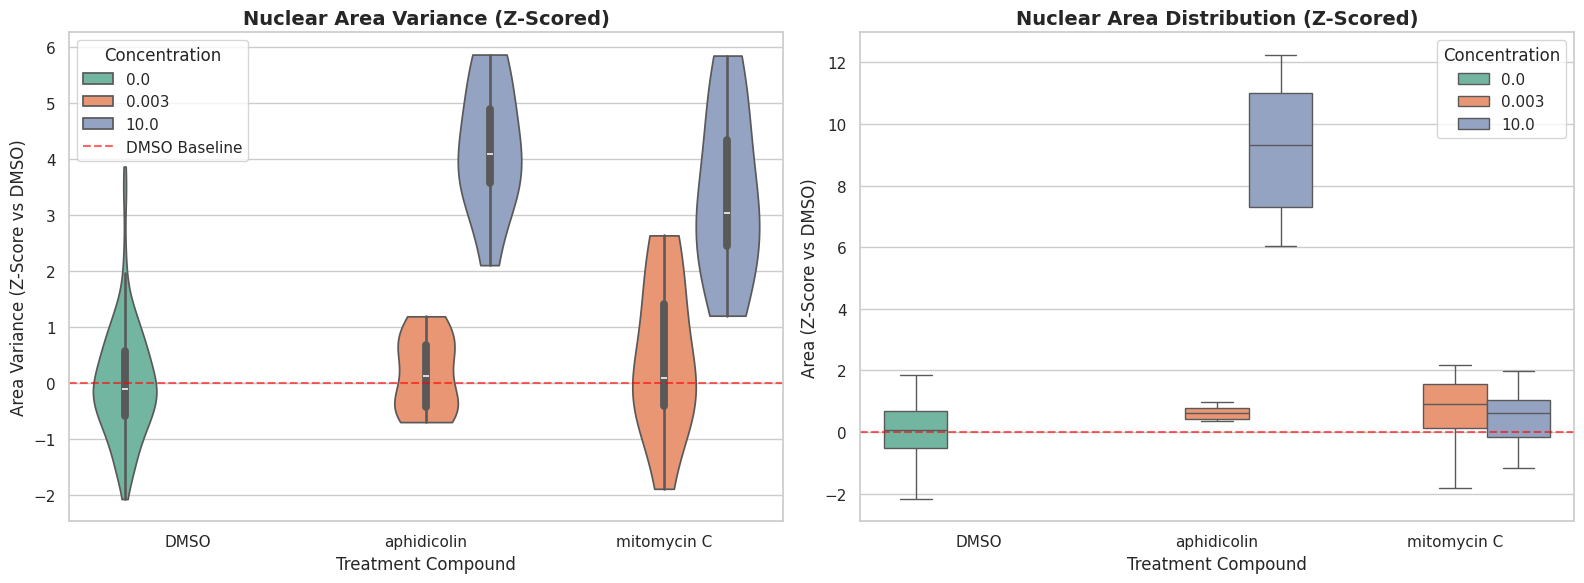

In [7]:
# 1. Load the normalized dataset
df = pd.read_csv("/content/drive/MyDrive/Final_Project-Imaging_SEGMENTED/Final_Project/bbbc021_zscored_features_per_plate.csv")
df = df.drop("label_zscore", axis=1)

# Ensure concentration is treated as a categorical string for cleaner plotting
df['concentration'] = df['concentration'].astype(str)

# Set up the visual style for publication-quality plots
sns.set_theme(style="whitegrid", palette="Set2")

# Create a figure with two subplots (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: Violin Plot for Nucleus Area ---
# Violin plots show the full distribution density, perfect for spotting bimodal cell populations
sns.violinplot(
    data=df,
    x='compound',
    y='area_variance_zscore',
    hue='concentration',
    ax=axes[0],
    cut=0,         # Prevents the tails from extending past the actual data limits
    density_norm='width' # Ensures violins have the same width
)
axes[0].set_title('Nuclear Area Variance (Z-Scored)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Area Variance (Z-Score vs DMSO)', fontsize=12)
axes[0].set_xlabel('Treatment Compound', fontsize=12)
axes[0].axhline(0, color='red', linestyle='--', alpha=0.6, label='DMSO Baseline')
axes[0].legend(title='Concentration')

# --- Plot 2: Boxplot for Mean Intensity ---
# Boxplots are great for seeing the median shifts and interquartile ranges
sns.boxplot(
    data=df,
    x='compound',
    y='area_zscore',
    hue='concentration',
    ax=axes[1],
    showfliers=False # Hides extreme outliers so the main box is easier to read
)
axes[1].set_title('Nuclear Area Distribution (Z-Scored)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Area (Z-Score vs DMSO)', fontsize=12)
axes[1].set_xlabel('Treatment Compound', fontsize=12)
axes[1].axhline(0, color='red', linestyle='--', alpha=0.6)
axes[1].legend(title='Concentration')

# Adjust layout to prevent overlap and display the plots
plt.tight_layout()
plt.show()

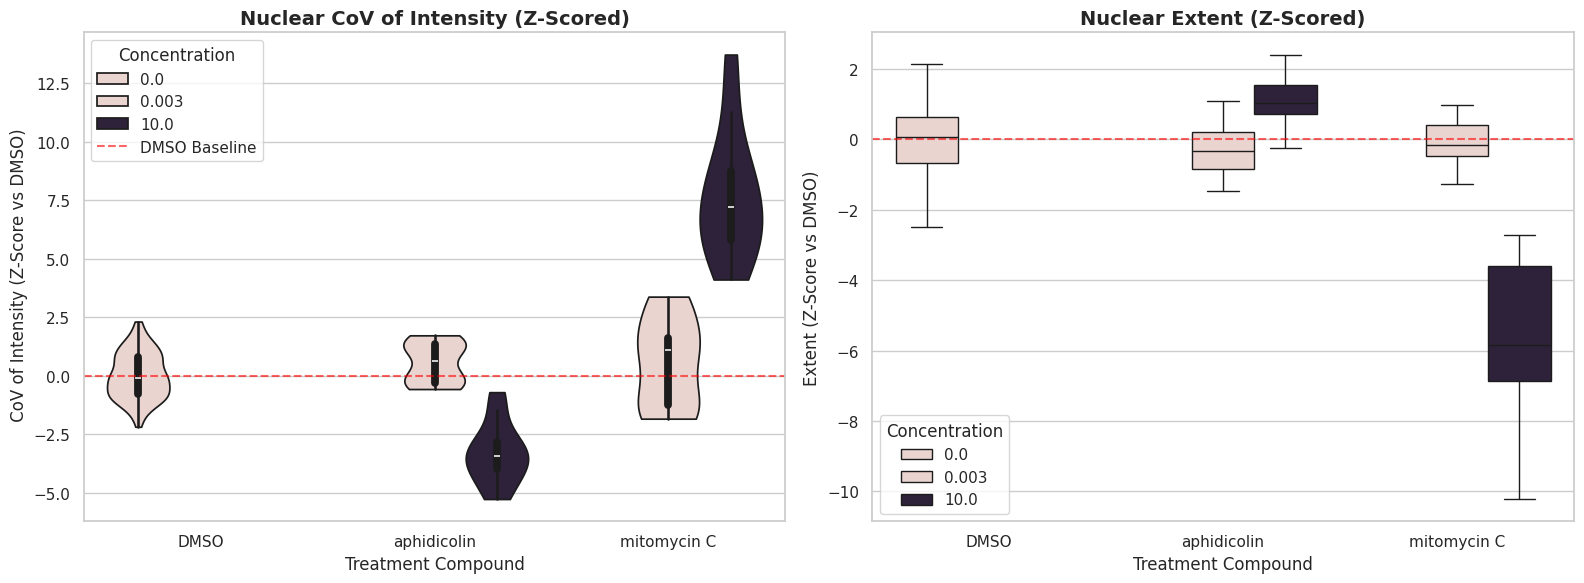

In [27]:
# Create a figure with two subplots (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: Violin Plot for Nucleus Area ---
# Violin plots show the full distribution density, perfect for spotting bimodal cell populations
sns.violinplot(
    data=df,
    x='compound',
    y='coefficient_of_variation_zscore',
    hue='concentration',
    ax=axes[0],
    cut=0,         # Prevents the tails from extending past the actual data limits
    density_norm='width' # Ensures violins have the same width
)
axes[0].set_title('Nuclear CoV of Intensity (Z-Scored)', fontsize=14, fontweight='bold')
axes[0].set_ylabel(' CoV of Intensity (Z-Score vs DMSO)', fontsize=12)
axes[0].set_xlabel('Treatment Compound', fontsize=12)
axes[0].axhline(0, color='red', linestyle='--', alpha=0.6, label='DMSO Baseline')
axes[0].legend(title='Concentration')

# --- Plot 2: Boxplot for Mean Intensity ---
# Boxplots are great for seeing the median shifts and interquartile ranges
sns.boxplot(
    data=df,
    x='compound',
    y='extent_zscore',
    hue='concentration',
    ax=axes[1],
    showfliers=False # Hides extreme outliers so the main box is easier to read
)
axes[1].set_title('Nuclear Extent (Z-Scored)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Extent (Z-Score vs DMSO)', fontsize=12)
axes[1].set_xlabel('Treatment Compound', fontsize=12)
axes[1].axhline(0, color='red', linestyle='--', alpha=0.6)
axes[1].legend(title='Concentration')

# Adjust layout to prevent overlap and display the plots
plt.tight_layout()
plt.show()

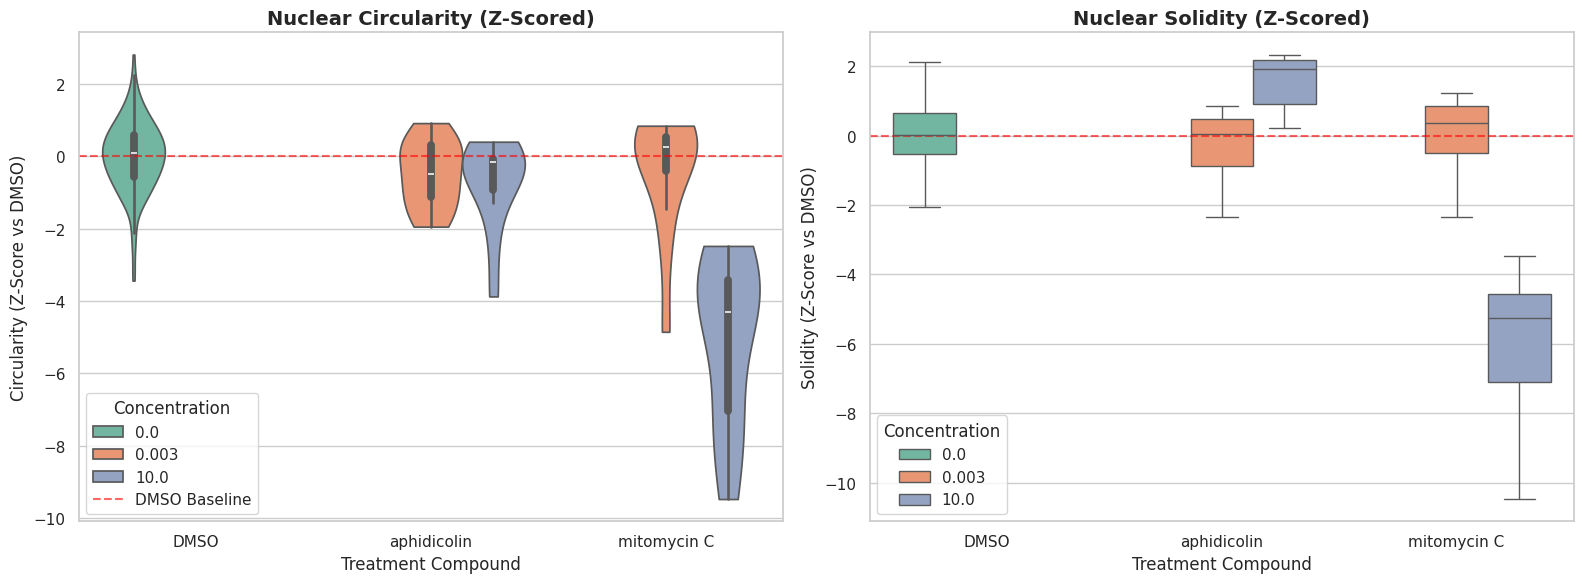

In [9]:
# Create a figure with two subplots (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: Violin Plot for Nucleus Area ---
# Violin plots show the full distribution density, perfect for spotting bimodal cell populations
sns.violinplot(
    data=df,
    x='compound',
    y='circularity_zscore',
    hue='concentration',
    ax=axes[0],
    cut=0,         # Prevents the tails from extending past the actual data limits
    density_norm='width' # Ensures violins have the same width
)
axes[0].set_title('Nuclear Circularity (Z-Scored)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Circularity (Z-Score vs DMSO)', fontsize=12)
axes[0].set_xlabel('Treatment Compound', fontsize=12)
axes[0].axhline(0, color='red', linestyle='--', alpha=0.6, label='DMSO Baseline')
axes[0].legend(title='Concentration')

# --- Plot 2: Boxplot for Mean Intensity ---
# Boxplots are great for seeing the median shifts and interquartile ranges
sns.boxplot(
    data=df,
    x='compound',
    y='solidity_zscore',
    hue='concentration',
    ax=axes[1],
    showfliers=False # Hides extreme outliers so the main box is easier to read
)
axes[1].set_title('Nuclear Solidity (Z-Scored)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Solidity (Z-Score vs DMSO)', fontsize=12)
axes[1].set_xlabel('Treatment Compound', fontsize=12)
axes[1].axhline(0, color='red', linestyle='--', alpha=0.6)
axes[1].legend(title='Concentration')

# Adjust layout to prevent overlap and display the plots
plt.tight_layout()
plt.show()

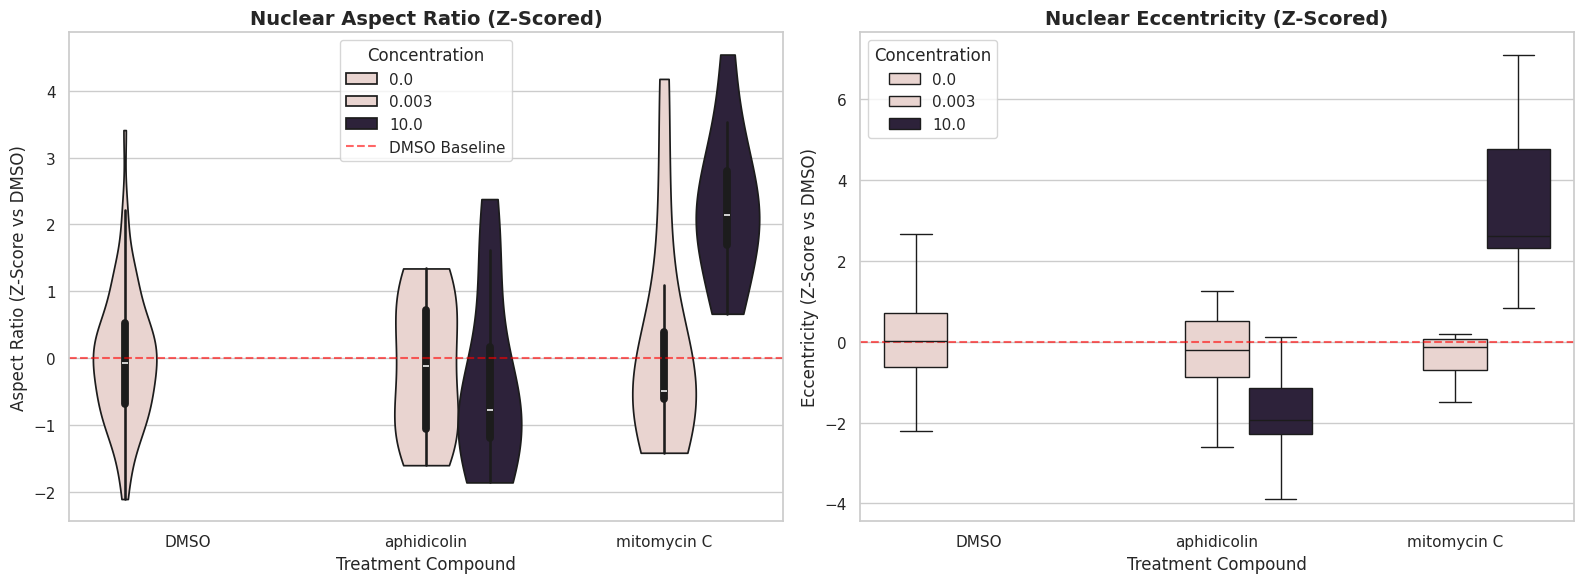

In [22]:
# Create a figure with two subplots (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: Violin Plot for Nucleus Area ---
# Violin plots show the full distribution density, perfect for spotting bimodal cell populations
sns.violinplot(
    data=df,
    x='compound',
    y='aspect_ratio_zscore',
    hue='concentration',
    ax=axes[0],
    cut=0,         # Prevents the tails from extending past the actual data limits
    density_norm='width' # Ensures violins have the same width
)
axes[0].set_title('Nuclear Aspect Ratio (Z-Scored)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Aspect Ratio (Z-Score vs DMSO)', fontsize=12)
axes[0].set_xlabel('Treatment Compound', fontsize=12)
axes[0].axhline(0, color='red', linestyle='--', alpha=0.6, label='DMSO Baseline')
axes[0].legend(title='Concentration')

# --- Plot 2: Boxplot for Mean Intensity ---
# Boxplots are great for seeing the median shifts and interquartile ranges
sns.boxplot(
    data=df,
    x='compound',
    y='eccentricity_zscore',
    hue='concentration',
    ax=axes[1],
    showfliers=False # Hides extreme outliers so the main box is easier to read
)
axes[1].set_title('Nuclear Eccentricity (Z-Scored)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Eccentricity (Z-Score vs DMSO)', fontsize=12)
axes[1].set_xlabel('Treatment Compound', fontsize=12)
axes[1].axhline(0, color='red', linestyle='--', alpha=0.6)
axes[1].legend(title='Concentration')

# Adjust layout to prevent overlap and display the plots
plt.tight_layout()
plt.show()

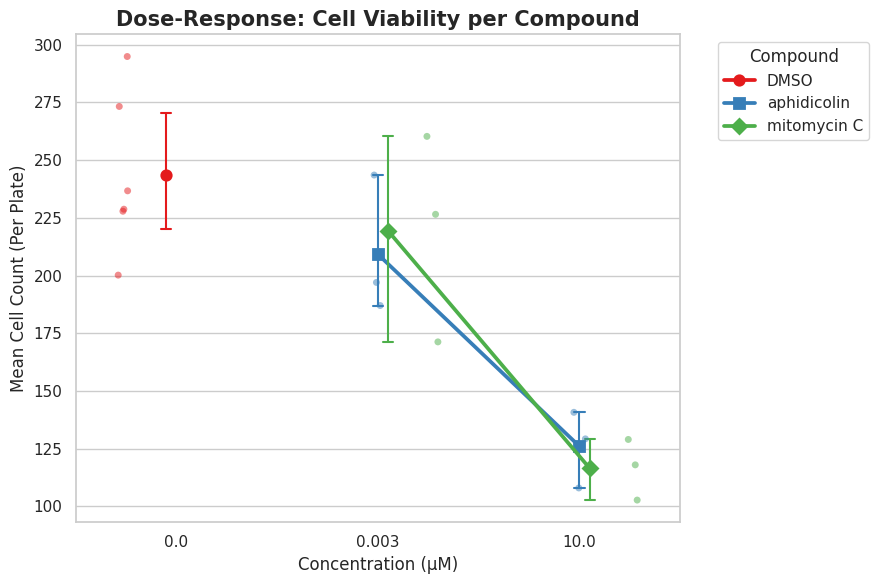

In [10]:
# Group to get the mean cell count PER PLATE (your biological replicates)
mean_counts = df.groupby(['compound', 'concentration', 'Plate ID'])['cell_count'].mean().reset_index()

# Ensure concentration is treated as a categorical variable but ordered correctly
# (0.0 first, then 0.003, then 10.0)
# First convert the column to floats so the numbers match perfectly
mean_counts['concentration'] = mean_counts['concentration'].astype(float)
# Then set them as ordered categories
mean_counts['concentration'] = pd.Categorical(mean_counts['concentration'], categories=[0.0, 0.003, 10.0], ordered=True)
# 2. Set up the plot
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 6))

# 3. Create the Trajectory Lines (Point Plot)
# This connects the overall averages and shows the standard deviation error bars
sns.pointplot(
    data=mean_counts,
    x='concentration',
    y='cell_count',
    hue='compound',
    dodge=0.1,             # Slightly separates the overlapping points
    markers=['o', 's', 'D'], # Different shapes for different compounds
    capsize=0.05,
    err_kws={'linewidth': 1.5},
    palette='Set1'
)

# 4. Overlay the Individual Plates (Strip Plot)
# This plots your actual 3 plate means as translucent dots around the main line
sns.stripplot(
    data=mean_counts,
    x='concentration',
    y='cell_count',
    hue='compound',
    dodge=0.1,
    alpha=0.5,             # Makes the individual plates slightly transparent
    palette='Set1',
    legend=False           # Prevents duplicate legend entries
)

# 5. Clean up formatting
plt.title('Dose-Response: Cell Viability per Compound', fontsize=15, fontweight='bold')
plt.ylabel('Mean Cell Count (Per Plate)', fontsize=12)
plt.xlabel('Concentration (µM)', fontsize=12)

# Fix the legend location
plt.legend(title='Compound', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# Principal Component Analysis (PCA)

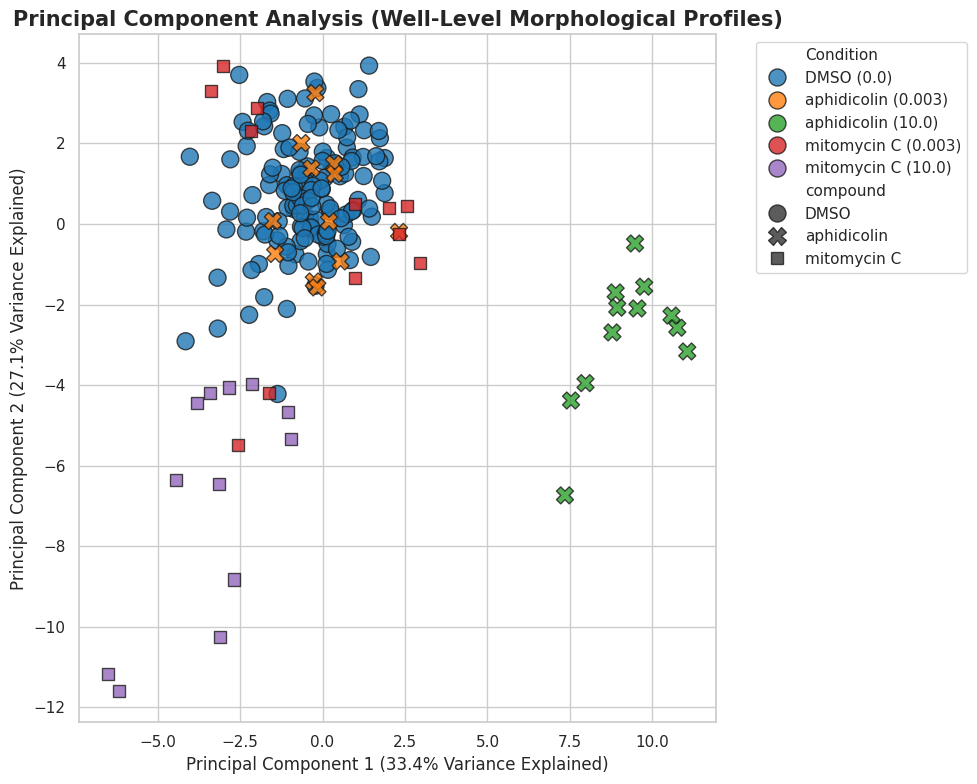

In [13]:
# 1. Load the dataset
df = pd.read_csv("/content/drive/MyDrive/Final_Project-Imaging_SEGMENTED/Final_Project/bbbc021_zscored_features_per_plate.csv")

# Clean up concentration and create a combined "Condition" label for the legend
df = df.drop("label_zscore", axis=1)
df['concentration'] = df['concentration'].astype(float)
df['Condition'] = df['compound'] + " (" + df['concentration'].astype(str) + ")"

# 2. Isolate the numerical feature columns (ignoring metadata and 'label_zscore')
features = [col for col in df.columns if '_zscore' in col and 'label' not in col]

# 3. Aggregate data to the Well-Level (calculates the mean of every feature per well)
well_df = df.groupby(['Condition', 'compound', 'concentration', 'well_name', 'Plate ID'])[features].mean().reset_index()

# Extract just the numerical matrix for PCA and fill any potential NaNs with 0
X = well_df[features].fillna(0)

# 4. Standardize the features
# Even though we Z-scored per plate, it is strictly required to run StandardScaler
# right before PCA so every feature has equal weight in the algorithm.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Run PCA
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_scaled)

# Add the resulting Principal Components back to our dataframe
well_df['PC1'] = pcs[:, 0]
well_df['PC2'] = pcs[:, 1]

# Calculate how much variance is explained by these two components
var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100

# 6. Plot the PCA
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 8))

# Use a scatter plot, styling markers by compound and colors by concentration
sns.scatterplot(
    data=well_df,
    x='PC1',
    y='PC2',
    hue='Condition',
    style='compound',
    s=150,           # Marker size
    alpha=0.8,
    edgecolor='k',   # Adds a nice border to the dots
    palette='tab10'
)

# Formatting
plt.title('Principal Component Analysis (Well-Level Morphological Profiles)', fontsize=15, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({var_pc1:.1f}% Variance Explained)', fontsize=12)
plt.ylabel(f'Principal Component 2 ({var_pc2:.1f}% Variance Explained)', fontsize=12)

# Move legend outside the plot
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

# Statistical Testing, ANOVA

In [18]:
# 1. Load the dataset
df = pd.read_csv("/content/drive/MyDrive/Final_Project-Imaging_SEGMENTED/Final_Project/bbbc021_zscored_features_per_plate.csv")
df = df.drop("label_zscore", axis=1)

df['concentration'] = df['concentration'].astype(float)

# 2. Filter for the baseline and the high-dose treatments
target_conditions = [
    (df['compound'] == 'DMSO') & (df['concentration'] == 0.0),
    (df['compound'] == 'aphidicolin') & (df['concentration'] == 10.0),
    (df['compound'] == 'mitomycin C') & (df['concentration'] == 10.0)
]
filtered_df = df[target_conditions[0] | target_conditions[1] | target_conditions[2]].copy()
filtered_df['Group'] = filtered_df['compound'] + " (" + filtered_df['concentration'].astype(str) + ")"

# 3. Aggregate to the IMAGE (Site) Level
# Because your 'well_name' column actually holds the .tif filenames,
# this groups the cells by the specific image they came from.
image_data = filtered_df.groupby(['Group', 'well_name', 'Plate ID'])['area_zscore'].mean().reset_index()

min_n = image_data['Group'].value_counts().min()

balanced_data = (
    image_data.groupby('Group', group_keys=False)
    .apply(lambda x: x.sample(min_n, random_state=42))
)

# Verify the sample sizes!
print("--- BALANCED OBSERVATIONS (Images) PER GROUP ---")
print(balanced_data['Group'].value_counts())
print("\n")

# 4. Extract the arrays for ANOVA
group_dmso = balanced_data[balanced_data['Group'] == 'DMSO (0.0)']['area_zscore']
group_aphi = balanced_data[balanced_data['Group'] == 'aphidicolin (10.0)']['area_zscore']
group_mito = balanced_data[balanced_data['Group'] == 'mitomycin C (10.0)']['area_zscore']

# 5. Run One-Way ANOVA
f_stat, p_value = stats.f_oneway(group_dmso, group_aphi, group_mito)
print("--- ONE-WAY ANOVA ON AREA ---")
print(f"F-statistic: {f_stat:.2f}")
print(f"P-value: {p_value:.2e}\n")

# 6. Run Tukey's HSD Post-Hoc Test
print(f"--- TUKEY HSD POST-HOC TEST ON AREA ---")
tukey_results = pairwise_tukeyhsd(
    endog=balanced_data['area_zscore'],
    groups=balanced_data['Group'],
    alpha=0.05
)
print(tukey_results)

--- BALANCED OBSERVATIONS (Images) PER GROUP ---
Group
DMSO (0.0)            12
aphidicolin (10.0)    12
mitomycin C (10.0)    12
Name: count, dtype: int64


--- ONE-WAY ANOVA ON AREA ---
F-statistic: 141.38
P-value: 6.55e-17

--- TUKEY HSD POST-HOC TEST ON AREA ---
             Multiple Comparison of Means - Tukey HSD, FWER=0.05             
      group1             group2       meandiff p-adj   lower    upper  reject
-----------------------------------------------------------------------------
        DMSO (0.0) aphidicolin (10.0)   9.1605    0.0   7.6447 10.6762   True
        DMSO (0.0) mitomycin C (10.0)   0.3393 0.8475  -1.1764  1.8551  False
aphidicolin (10.0) mitomycin C (10.0)  -8.8212    0.0 -10.3369 -7.3054   True
-----------------------------------------------------------------------------


/tmp/ipykernel_307/3135582092.py:25: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min_n, random_state=42))


In [19]:
image_data = filtered_df.groupby(['Group', 'well_name', 'Plate ID'])['area_variance_zscore'].mean().reset_index()

min_n = image_data['Group'].value_counts().min()

balanced_data = (
    image_data.groupby('Group', group_keys=False)
    .apply(lambda x: x.sample(min_n, random_state=42))
)

# Verify the sample sizes!
print("--- BALANCED OBSERVATIONS (Images) PER GROUP ---")
print(balanced_data['Group'].value_counts())
print("\n")

# 4. Extract the arrays for ANOVA
group_dmso = balanced_data[balanced_data['Group'] == 'DMSO (0.0)']['area_variance_zscore']
group_aphi = balanced_data[balanced_data['Group'] == 'aphidicolin (10.0)']['area_variance_zscore']
group_mito = balanced_data[balanced_data['Group'] == 'mitomycin C (10.0)']['area_variance_zscore']

# 5. Run One-Way ANOVA
f_stat, p_value = stats.f_oneway(group_dmso, group_aphi, group_mito)
print("--- ONE-WAY ANOVA ON AREA Variance ---")
print(f"F-statistic: {f_stat:.2f}")
print(f"P-value: {p_value:.2e}\n")

# 6. Run Tukey's HSD Post-Hoc Test
print(f"--- TUKEY HSD POST-HOC TEST ON AREA Variance ---")
tukey_results = pairwise_tukeyhsd(endog=balanced_data['area_variance_zscore'], groups=balanced_data['Group'], alpha=0.05)
print(tukey_results)

--- BALANCED OBSERVATIONS (Images) PER GROUP ---
Group
DMSO (0.0)            12
aphidicolin (10.0)    12
mitomycin C (10.0)    12
Name: count, dtype: int64


--- ONE-WAY ANOVA ON AREA Variance ---
F-statistic: 42.16
P-value: 8.15e-10

--- TUKEY HSD POST-HOC TEST ON AREA Variance ---
           Multiple Comparison of Means - Tukey HSD, FWER=0.05            
      group1             group2       meandiff p-adj  lower  upper  reject
--------------------------------------------------------------------------
        DMSO (0.0) aphidicolin (10.0)   4.2021   0.0  3.0157 5.3884   True
        DMSO (0.0) mitomycin C (10.0)   3.3416   0.0  2.1552 4.5279   True
aphidicolin (10.0) mitomycin C (10.0)  -0.8605 0.192 -2.0469 0.3258  False
--------------------------------------------------------------------------


/tmp/ipykernel_307/44561881.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min_n, random_state=42))


In [20]:
image_data = filtered_df.groupby(['Group', 'well_name', 'Plate ID'])['circularity_zscore'].mean().reset_index()

min_n = image_data['Group'].value_counts().min()

balanced_data = (
    image_data.groupby('Group', group_keys=False)
    .apply(lambda x: x.sample(min_n, random_state=42))
)

# Verify the sample sizes!
print("--- BALANCED OBSERVATIONS (Images) PER GROUP ---")
print(balanced_data['Group'].value_counts())
print("\n")


# 4. Extract the arrays for ANOVA
group_dmso = balanced_data[balanced_data['Group'] == 'DMSO (0.0)']['circularity_zscore']
group_aphi = balanced_data[balanced_data['Group'] == 'aphidicolin (10.0)']['circularity_zscore']
group_mito = balanced_data[balanced_data['Group'] == 'mitomycin C (10.0)']['circularity_zscore']

# 5. Run One-Way ANOVA
f_stat, p_value = stats.f_oneway(group_dmso, group_aphi, group_mito)
print(f"--- ONE-WAY ANOVA on Circularity ---")
print(f"F-statistic: {f_stat:.2f}")
print(f"P-value: {p_value:.2e}\n")

# 6. Run Tukey's HSD Post-Hoc Test
print(f"--- TUKEY HSD POST-HOC TEST ON Circularity ---")
tukey_results = pairwise_tukeyhsd(endog=balanced_data['circularity_zscore'], groups=balanced_data['Group'], alpha=0.05)
print(tukey_results)

--- BALANCED OBSERVATIONS (Images) PER GROUP ---
Group
DMSO (0.0)            12
aphidicolin (10.0)    12
mitomycin C (10.0)    12
Name: count, dtype: int64


--- ONE-WAY ANOVA on Circularity ---
F-statistic: 36.27
P-value: 4.67e-09

--- TUKEY HSD POST-HOC TEST ON Circularity ---
            Multiple Comparison of Means - Tukey HSD, FWER=0.05            
      group1             group2       meandiff p-adj  lower   upper  reject
---------------------------------------------------------------------------
        DMSO (0.0) aphidicolin (10.0)  -0.7145 0.503 -2.2665  0.8375  False
        DMSO (0.0) mitomycin C (10.0)  -4.9809   0.0 -6.5329 -3.4289   True
aphidicolin (10.0) mitomycin C (10.0)  -4.2664   0.0 -5.8184 -2.7144   True
---------------------------------------------------------------------------


/tmp/ipykernel_307/3452005786.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min_n, random_state=42))


In [21]:
image_data = filtered_df.groupby(['Group', 'well_name', 'Plate ID'])['solidity_zscore'].mean().reset_index()

min_n = image_data['Group'].value_counts().min()

balanced_data = (
    image_data.groupby('Group', group_keys=False)
    .apply(lambda x: x.sample(min_n, random_state=42))
)

# Verify the sample sizes!
print("--- BALANCED OBSERVATIONS (Images) PER GROUP ---")
print(balanced_data['Group'].value_counts())
print("\n")

# 4. Extract the arrays for ANOVA
group_dmso = balanced_data[balanced_data['Group'] == 'DMSO (0.0)']['solidity_zscore']
group_aphi = balanced_data[balanced_data['Group'] == 'aphidicolin (10.0)']['solidity_zscore']
group_mito = balanced_data[balanced_data['Group'] == 'mitomycin C (10.0)']['solidity_zscore']

# 5. Run One-Way ANOVA
f_stat, p_value = stats.f_oneway(group_dmso, group_aphi, group_mito)
print(f"--- ONE-WAY ANOVA on Solidity ---")
print(f"F-statistic: {f_stat:.2f}")
print(f"P-value: {p_value:.2e}\n")

# 6. Run Tukey's HSD Post-Hoc Test
print(f"--- TUKEY HSD POST-HOC TEST ON Solidity ---")
tukey_results = pairwise_tukeyhsd(endog=balanced_data['solidity_zscore'], groups=balanced_data['Group'], alpha=0.05)
print(tukey_results)

/tmp/ipykernel_307/3567596446.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min_n, random_state=42))


--- BALANCED OBSERVATIONS (Images) PER GROUP ---
Group
DMSO (0.0)            12
aphidicolin (10.0)    12
mitomycin C (10.0)    12
Name: count, dtype: int64


--- ONE-WAY ANOVA on Solidity ---
F-statistic: 82.79
P-value: 1.38e-13

--- TUKEY HSD POST-HOC TEST ON Solidity ---
            Multiple Comparison of Means - Tukey HSD, FWER=0.05            
      group1             group2       meandiff p-adj  lower   upper  reject
---------------------------------------------------------------------------
        DMSO (0.0) aphidicolin (10.0)   1.3783 0.076 -0.1186  2.8752  False
        DMSO (0.0) mitomycin C (10.0)  -6.0031   0.0    -7.5 -4.5063   True
aphidicolin (10.0) mitomycin C (10.0)  -7.3814   0.0 -8.8783 -5.8846   True
---------------------------------------------------------------------------
